In [22]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt 
%matplotlib inline
import seaborn as sns
from sklearn.preprocessing import LabelEncoder
from sklearn.ensemble import RandomForestRegressor


In [14]:
df = pd.read_csv("E:/shopping_trends(1).csv")

In [15]:
df

,Customer ID,Age,Gender,Item Purchased,Category,Purchase Amount (USD),Location,Size,Color,Season,Review Rating,Subscription Status,Payment Method,Shipping Type,Discount Applied,Promo Code Used,Previous Purchases,Preferred Payment Method,Frequency of Purchases
0,1,55,Male,Blouse,Clothing,53,Kentucky,L,Gray,Winter,3.1,Yes,Credit Card,Express,Yes,Yes,14,Venmo,Fortnightly
1,2,19,Male,Sweater,Clothing,64,Maine,L,Maroon,Winter,3.1,Yes,Bank Transfer,Express,Yes,Yes,2,Cash,Fortnightly
2,3,50,Male,Jeans,Clothing,73,Massachusetts,S,Maroon,Spring,3.1,Yes,Cash,Free Shipping,Yes,Yes,23,Credit Card,Weekly
3,4,21,Male,Sandals,Footwear,90,Rhode Island,M,Maroon,Spring,3.5,Yes,PayPal,Next Day Air,Yes,Yes,49,PayPal,Weekly
4,5,45,Male,Blouse,Clothing,49,Oregon,M,Turquoise,Spring,2.7,Yes,Cash,Free Shipping,Yes,Yes,31,PayPal,Annually
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
3895,3896,40,Female,Hoodie,Clothing,28,Virginia,L,Turquoise,Summer,4.2,No,Cash,2-Day Shipping,No,No,32,Venmo,Weekly
3896,3897,52,Female,Backpack,Accessories,49,Iowa,L,White,Spring,4.5,No,PayPal,Store Pickup,No,No,41,Bank Transfer,Bi-Weekly
3897,3898,46,Female,Belt,Accessories,33,New Jersey,L,Green,Spring,2.9,No,Credit Card,Standard,No,No,24,Venmo,Quarterly
3898,3899,44,Female,Shoes,Footwear,77,Minnesota,S,Brown,Summer,3.8,No,PayPal,Express,No,No,24,Venmo,Weekly


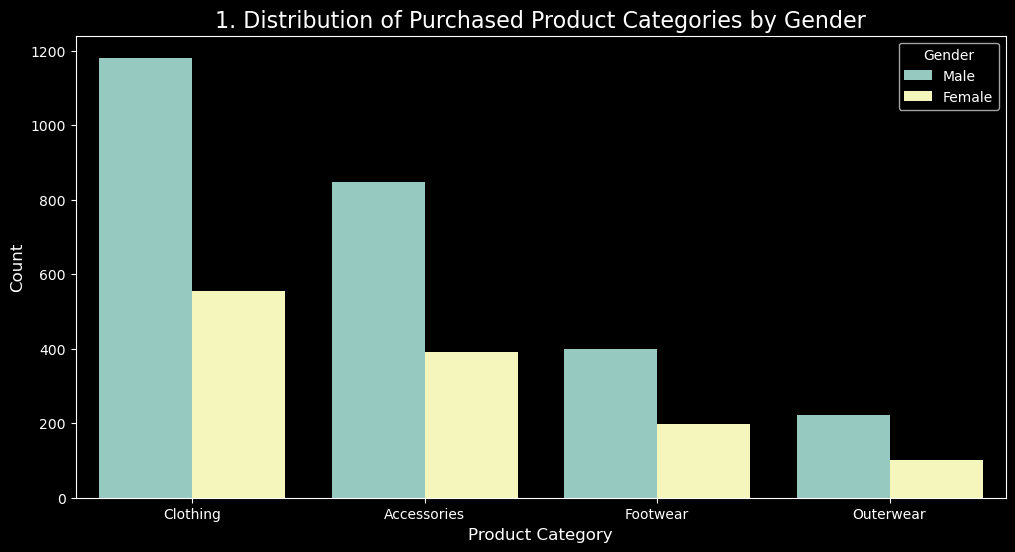

In [18]:
plt.style.use('dark_background')
plt.figure(figsize=(12, 6))

sns.countplot(
    data=df,
    x='Category',
    hue='Gender',
    order=df['Category'].value_counts().index
)

plt.title('1. Distribution of Purchased Product Categories by Gender', fontsize=16)
plt.xlabel('Product Category', fontsize=12)
plt.ylabel('Count', fontsize=12)
plt.show()

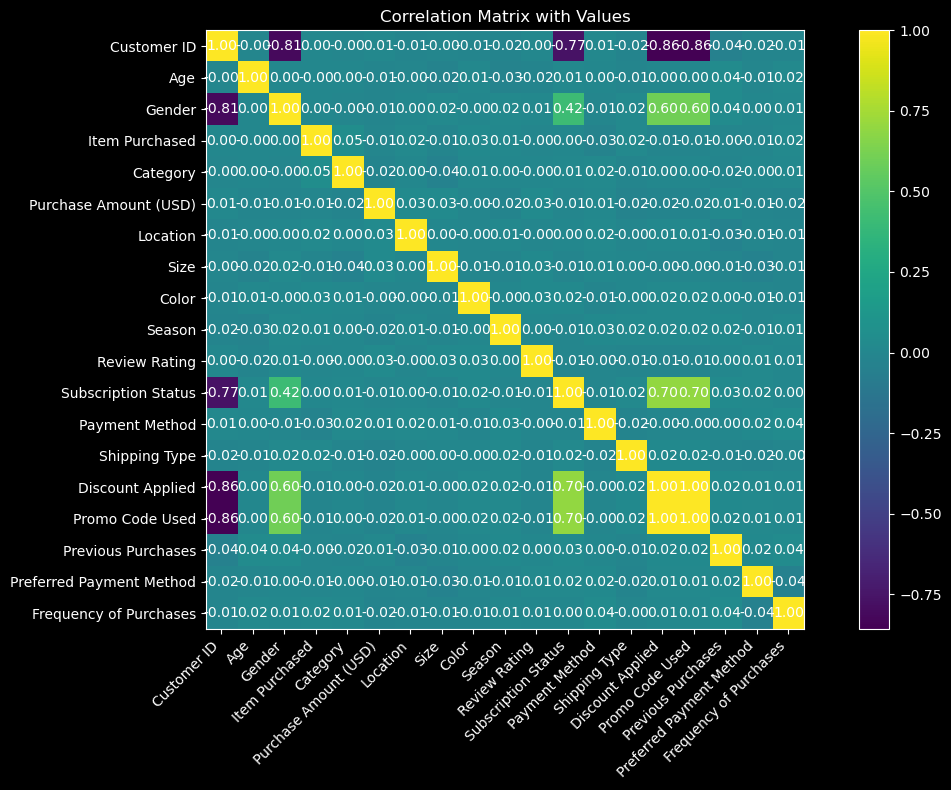

In [19]:

label_enc = LabelEncoder()
for col in df.columns:
    if df[col].dtype == 'object':
        df[col] = label_enc.fit_transform(df[col].astype(str))

# --- Correlation ---
corr = df.corr()

# --- Plot Heatmap ---
plt.figure(figsize=(12, 8))
plt.imshow(corr, cmap='viridis')
plt.colorbar()

# X/Y ticks
plt.xticks(range(len(corr)), corr.columns, rotation=45, ha='right')
plt.yticks(range(len(corr)), corr.columns)

# --- Add numbers inside cells ---
for i in range(len(corr)):
    for j in range(len(corr)):
        plt.text(j, i, f"{corr.iloc[i, j]:.2f}",
                 ha='center', va='center', color='white', fontsize=10)

plt.title("Correlation Matrix with Values")
plt.tight_layout()
plt.show()

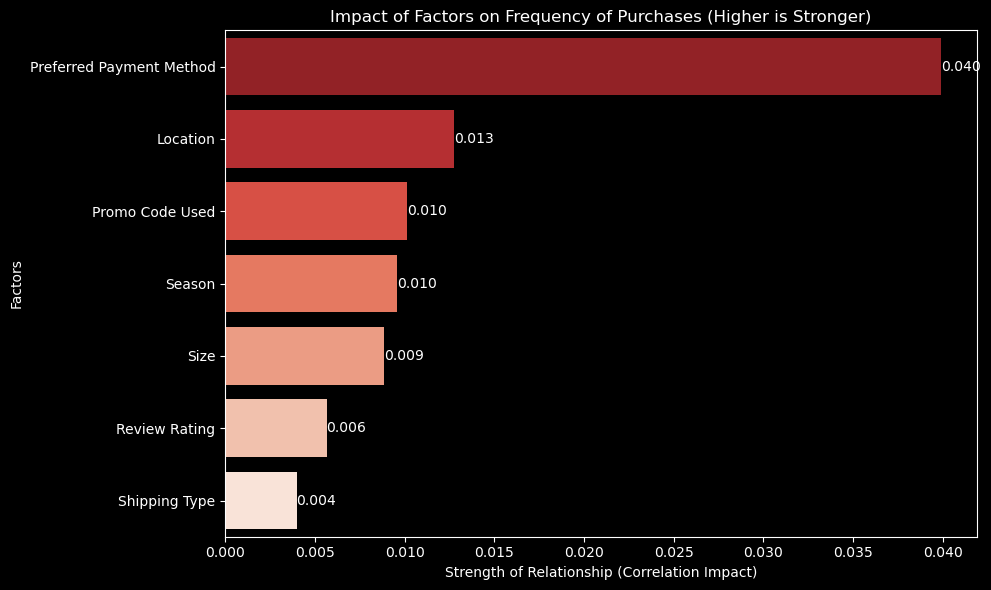

In [27]:
features = [
    'Location', 'Size', 'Season', 'Review Rating', 
    'Shipping Type', 'Promo Code Used', 'Preferred Payment Method',
    'Frequency of Purchases' ]

df_analysis = df[features].copy()


le = LabelEncoder()
for col in df_analysis.columns:
    if df_analysis[col].dtype == 'object':
        df_analysis[col] = le.fit_transform(df_analysis[col])


correlation = df_analysis.corr()['Frequency of Purchases'].drop('Frequency of Purchases').abs().sort_values(ascending=False)


plt.figure(figsize=(10, 6))
sns.barplot(x=correlation.values, y=correlation.index,hue=correlation.index, palette='Reds_r')

plt.title('Impact of Factors on Frequency of Purchases (Higher is Stronger)')
plt.xlabel('Strength of Relationship (Correlation Impact)')
plt.ylabel('Factors')


for index, value in enumerate(correlation.values):
    plt.text(value, index, f'{value:.3f}', va='center')

plt.tight_layout()
plt.show()

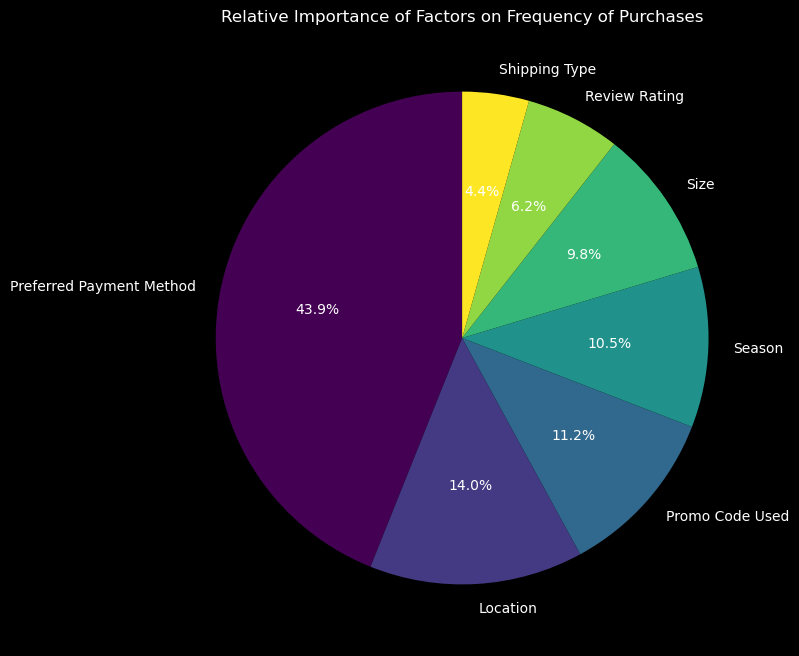

In [31]:
df = df.loc[:, ~df.columns.duplicated()]

# الأعمدة التي نريد قياس تأثيرها
cols = ['Location', 'Size', 'Season', 'Review Rating', 'Shipping Type', 'Promo Code Used', 'Preferred Payment Method']
target = 'Frequency of Purchases'

# التأكد من أن جميع الأعمدة المطلوبة موجودة في الملف
available_cols = [c for c in cols if c in df.columns]
if target not in df.columns:
    raise ValueError(f"Column '{target}' not found in dataset")

# 2. تحويل البيانات إلى أرقام
df_encoded = df[available_cols + [target]].copy()
le = LabelEncoder()

for col in df_encoded.columns:
    # نتأكد أننا نتعامل مع عمود واحد (Series) وليس داتا فريم
    if isinstance(df_encoded[col], pd.DataFrame):
        # في حالة نادرة جداً لو التكرار لسه موجود، نأخذ أول نسخة فقط
        df_encoded[col] = df_encoded[col].iloc[:, 0]
        
    if df_encoded[col].dtype == 'object':
        df_encoded[col] = le.fit_transform(df_encoded[col])

# 3. حساب الارتباط (Correlations)
# نحسب علاقة كل عمود بالـ Target، ونأخذ القيمة المطلقة (abs)
correlations = df_encoded.corr()[target].abs().drop(target)

# ترتيب القيم
correlations = correlations.sort_values(ascending=False)

# 4. الرسم البياني (Pie Chart)
plt.figure(figsize=(10, 8))
plt.pie(
    correlations, 
    labels=correlations.index, 
    autopct='%1.1f%%', 
    startangle=90,
    colors=plt.cm.viridis(np.linspace(0, 1, len(correlations)))
)

plt.title('Relative Importance of Factors on Frequency of Purchases')
plt.show()